# Explorative Datenanalyse: `rfd_main.csv`

Dieses Notebook führt eine vollständige, schrittweise explorative Analyse (EDA) des
Rohdatensatzes durch, der als Datengrundlage für die Masterarbeit *"KI-basierte
Datenbereinigung im Wandel"* dient (vgl. Abschnitt 3.1, Datengrundlage). Ziel ist es,
alle vier in der Arbeit untersuchten Fehlerarten -- Duplikate, fehlende Werte,
Formatierungsfehler und semantische Heterogenität -- systematisch und nachvollziehbar
zu belegen, bevor mit den eigentlichen Bereinigungsverfahren begonnen wird.

**Ablauf:**
1. Import und Laden der Daten
2. Grundlegende Struktur (Zeilen, Spalten, Datentypen)
3. Fehlende Werte
4. Duplikate
5. Numerische Spalten (Deskriptivstatistik, Ausreißer)
6. Kategoriale Spalten (parent_category, thread_category, source)
7. Formatierungsfehler (price, saving)
8. Semantische Heterogenität (thread_category vs. parent_category)
9. Zeitspalten (creation_date, expiry, last_reply)
10. Textspalte (title)
11. Zusammenfassung


## 1. Import und Laden der Daten

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from datetime import datetime

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

df = pd.read_csv("data/rfd_main.csv")
print(f"Datensatz geladen: {df.shape[0]} Zeilen, {df.shape[1]} Spalten")


Datensatz geladen: 1326 Zeilen, 15 Spalten


## 2. Grundlegende Struktur

### 2.1 Anzahl Zeilen und Spalten

In [ ]:
n_rows, n_cols = df.shape
print(f"Zeilen (Datensätze):  {n_rows}")
print(f"Spalten (Attribute):  {n_cols}")
print()
print("Spaltennamen:")
for i, c in enumerate(df.columns, 1):
    print(f"  {i:2d}. {c}")


Zeilen (Datensätze):  1326
Spalten (Attribute):  15

Spaltennamen:
   1. Unnamed: 0
   2. author
   3. creation_date
   4. expiry
   5. last_reply
   6. parent_category
   7. price
   8. replies
   9. saving
  10. source
  11. thread_category
  12. title
  13. url
  14. views
  15. votes


### 2.2 Vorschau der ersten und letzten Zeilen

In [ ]:
df.head(5)

,Unnamed: 0,author,creation_date,expiry,last_reply,parent_category,price,replies,saving,source,thread_category,title,url,views,votes
0,0,flora0222,"Jul 16th, 2020 8:29 am",NaN,"Jul 17th, 2020 9:20 am",NaN,6.99,89,NaN,Staples,Home & Garden,"One Step Hand Sanitizer, Fragrance-Free, 473mL...",https://staplescanada.4u8mqw.net/c/341376/7554...,15445,132
1,1,yellowmp5,"Jul 13th, 2020 1:29 pm",NaN,"Jul 17th, 2020 9:18 am",NaN,NaN,441,NaN,Home Depot,Home & Garden,RYOBI 20% coupon barcode,NaN,59219,159
2,2,riseagainstthemachine,"Jul 2nd, 2020 10:03 am",NaN,"Jul 17th, 2020 9:17 am",NaN,free,92,NaN,NaN,Apparel,Kits.com Free Pair Prescription Glasses,https://www.kits.com/freeglasses.html,25242,54
3,3,Googliya,"Jul 17th, 2020 7:23 am",NaN,"Jul 17th, 2020 9:15 am",NaN,469.99,13,NaN,Costco,Sports & Fitness,"Northrock xc00, fat Tire bike, $469.99",https://www.costco.ca/northrock-xc00-fat-tire-...,1769,2
4,4,Presents,"Jul 16th, 2020 1:36 pm","July 29, 2020","Jul 17th, 2020 9:15 am",NaN,NaN,24,NaN,Canadian Tire,Automotive,60x total CT Money when you pay with your Tria...,NaN,2981,9


In [ ]:
df.tail(5)

,Unnamed: 0,author,creation_date,expiry,last_reply,parent_category,price,replies,saving,source,thread_category,title,url,views,votes
1321,2,zobi123,"Jun 24th, 2020 5:46 pm",NaN,"Jun 25th, 2020 2:39 pm",Automotive,NaN,20,NaN,Amazon.ca,Auto Parts & Accessories,Noco Portable Jump Starter $112,http://www.amazon.ca/gp/redirect.html?ie=UTF8&...,3729,8
1322,3,alextch,"Jun 22nd, 2020 4:43 pm",NaN,"Jun 25th, 2020 2:06 pm",Sports & Fitness,599.99,54,NaN,Costco,Equipment,Marcy Cage Home Gym System $599.99,https://www.costco.ca/marcy-cage-home-gym-syst...,14865,22
1323,4,MichaelT26086,"Jun 13th, 2020 1:18 pm","September 1, 2020","Jun 13th, 2020 6:38 pm",NaN,NaN,2,50% off,NaN,Apparel,North Face Healthcare Workers 50% Discount on ...,http://go.redirectingat.com?id=2927x594702&amp...,3772,7
1324,5,Minimo07,"Apr 21st, 2020 2:36 pm","May 3, 2020","Apr 22nd, 2020 10:58 pm",NaN,19.99,27,$5 off,NaN,Groceries,Charmin Ultra Soft Bathroom Tissue 30 rolls $1...,NaN,4296,0
1325,6,hongsj,"Dec 25th, 2019 3:44 am",NaN,"Dec 25th, 2019 3:00 pm",Computers & Electronics,NaN,3,NaN,NaN,Cell Phones,"[Google] Pixel 4,4XL -200 3a,3aXL -150",https://store.google.com/ca/collection/offers,6382,0


### 2.3 Datentypen je Spalte

In [ ]:
dtype_overview = pd.DataFrame({
    "Spalte": df.columns,
    "Pandas-Dtype": df.dtypes.astype(str).values,
    "Nicht-null (n)": df.notna().sum().values,
    "Nicht-null (%)": (df.notna().mean().values * 100).round(1),
    "Eindeutige Werte": [df[c].nunique() for c in df.columns],
})
dtype_overview


,Spalte,Pandas-Dtype,Nicht-null (n),Nicht-null (%),Eindeutige Werte
0,Unnamed: 0,int64,1326,100.0,30
1,author,object,1326,100.0,946
2,creation_date,object,1326,100.0,1283
3,expiry,object,370,27.9,73
4,last_reply,object,1326,100.0,1253
5,parent_category,object,825,62.2,12
6,price,object,898,67.7,610
7,replies,int64,1326,100.0,210
8,saving,object,524,39.5,286
9,source,object,987,74.4,148


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1326 entries, 0 to 1325
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Unnamed: 0       1326 non-null   int64 
 1   author           1326 non-null   object
 2   creation_date    1326 non-null   object
 3   expiry           370 non-null    object
 4   last_reply       1326 non-null   object
 5   parent_category  825 non-null    object
 6   price            898 non-null    object
 7   replies          1326 non-null   int64 
 8   saving           524 non-null    object
 9   source           987 non-null    object
 10  thread_category  1325 non-null   object
 11  title            1326 non-null   object
 12  url              1044 non-null   object
 13  views            1326 non-null   int64 
 14  votes            1326 non-null   int64 
dtypes: int64(4), object(11)
memory usage: 155.5+ KB


**Hinweis:** Alle Spalten werden von pandas beim Einlesen zunächst als `object`
(Preis, Rabatt, Datum) oder `int64`/`float64` (Kennzahlen) erkannt. Dass Datumsspalten
(`creation_date`, `expiry`, `last_reply`) als `object` statt als `datetime` erkannt
werden, ist bereits ein erster Hinweis auf uneinheitliche Formatierung (vgl. Abschnitt 8).

## 3. Fehlende Werte

### 3.1 Fehlende Werte je Spalte (absolut und relativ)

In [ ]:
missing = pd.DataFrame({
    "fehlend (n)": df.isna().sum(),
    "fehlend (%)": (df.isna().mean() * 100).round(1),
}).sort_values("fehlend (%)", ascending=False)
missing = missing[missing["fehlend (n)"] > 0]
missing


,fehlend (n),fehlend (%)
expiry,956,72.1
saving,802,60.5
parent_category,501,37.8
price,428,32.3
source,339,25.6
url,282,21.3
thread_category,1,0.1


### 3.2 Visualisierung: Anteil fehlender Werte je Spalte

NameError: name 'missing' is not defined

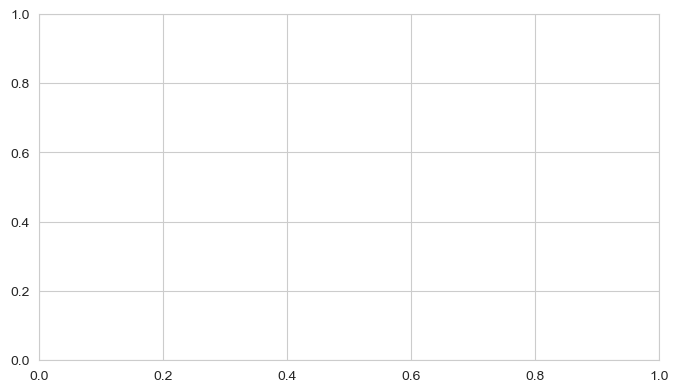

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
missing_sorted = missing.sort_values("fehlend (%)")
ax.barh(
    missing_sorted.index,
    missing_sorted["fehlend (%)"],
    color="#4C72B0"
)
ax.set_xlabel("Anteil fehlender Werte (%)")
ax.set_title("Fehlende Werte je Spalte")

for i, v in enumerate(missing_sorted["fehlend (%)"]):
    ax.text(v + 1, i, f"{v:.0f}%", va="center")

plt.tight_layout()

plt.savefig(
    "../images/Abbildung01_Fehlende_Werte_300DPI.png",
    dpi=300
)

plt.show()


### 3.3 Heatmap der fehlenden Werte (Muster über den Datensatz hinweg)

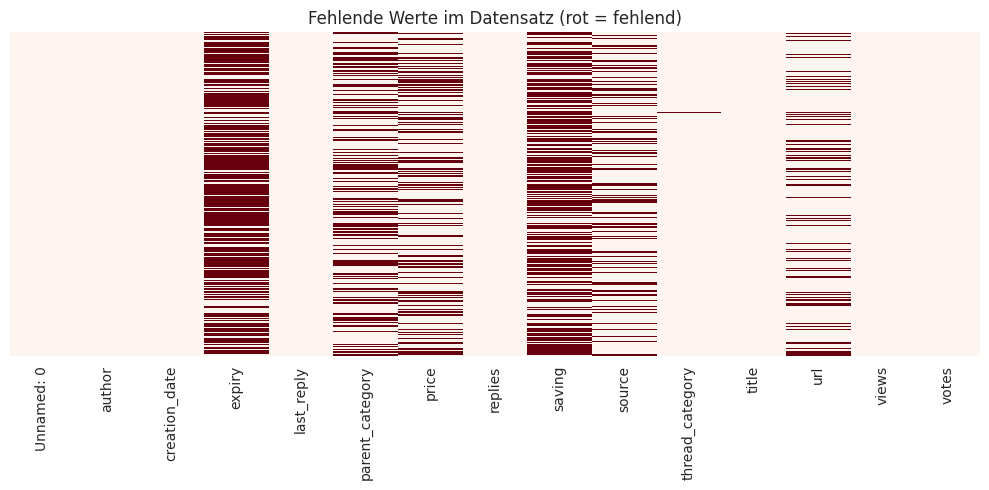

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="Reds", ax=ax)
ax.set_title("Fehlende Werte im Datensatz (rot = fehlend)")
plt.tight_layout()
plt.show()


### 3.4 Zusammenhang zwischen fehlenden Feldern (Ko-Auftreten)

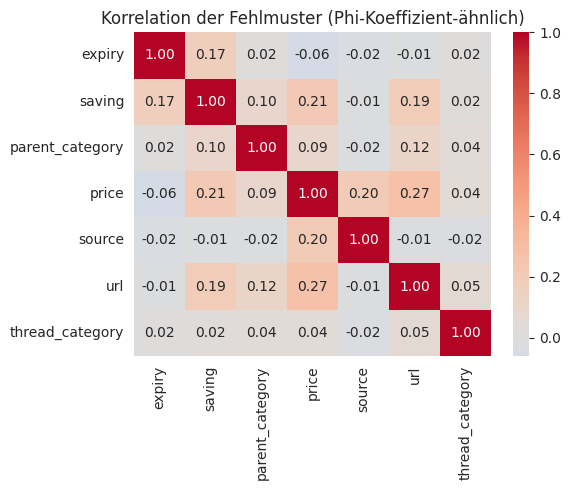

Positive Werte: die Spalten fehlen tendenziell gemeinsam.


In [ ]:
miss_cols = missing.index.tolist()
co_missing = df[miss_cols].isna().astype(int).corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(co_missing, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Korrelation der Fehlmuster (Phi-Koeffizient-ähnlich)")
plt.tight_layout()
plt.show()
print("Positive Werte: die Spalten fehlen tendenziell gemeinsam.")


## 4. Duplikate

### 4.1 Vollständig identische Zeilen

In [ ]:
n_exact_dupes = df.duplicated(keep=False).sum()
print(f"Vollständig identische Zeilen: {n_exact_dupes}")


Vollständig identische Zeilen: 0


### 4.2 Duplikate nach einzelnen Schlüsselspalten

In [ ]:
dup_checks = {
    "identischer Titel (title)": df.duplicated(subset=["title"], keep=False).sum(),
    "identische URL (url, ohne NaN)": df[df["url"].notna()].duplicated(subset=["url"], keep=False).sum(),
    "identischer Autor + Titel": df.duplicated(subset=["author", "title"], keep=False).sum(),
    "identischer Autor + Preis + Kategorie": df.duplicated(subset=["author", "price", "parent_category"], keep=False).sum(),
}
pd.DataFrame.from_dict(dup_checks, orient="index", columns=["Anzahl betroffener Zeilen"])


,Anzahl betroffener Zeilen
identischer Titel (title),34
"identische URL (url, ohne NaN)",50
identischer Autor + Titel,32
identischer Autor + Preis + Kategorie,157


### 4.3 Beispiele: Zeilen mit identischer URL

In [ ]:
url_dupes = df[df["url"].notna() & df.duplicated(subset=["url"], keep=False)].sort_values("url")
url_dupes[["title", "author", "creation_date", "price", "url"]].head(10)


,title,author,creation_date,price,url
23,Clarisonic - Shutting Down Sale - 50% Off Ever...,laughingoh,"Jul 14th, 2020 11:24 pm",NaN,http://clarisonicca.sjv.io/c/341376/344610/512...
29,Clarisonic - Shutting Down Sale - 50% Off Ever...,laughingoh,"Jul 14th, 2020 11:24 pm",NaN,http://clarisonicca.sjv.io/c/341376/344610/512...
1296,End of season sale - 50% off | GETEXTRA,michelangelo88,"Jun 23rd, 2020 10:33 am",NaN,http://reebok-canada.sjv.io/c/341376/356400/52...
533,"40% off outlet, 30% off select items Summer Sale",iced~metal,"Jul 11th, 2020 5:08 am",NaN,http://reebok-canada.sjv.io/c/341376/356400/52...
61,"AirHeads Bars, Chewy Fruit Candy, Variety Pack...",Stevebos,"Jul 17th, 2020 5:30 am",7.46,http://www.amazon.ca/gp/redirect.html?ie=UTF8&...
60,"AirHeads Bars, 60 Count 7.46$ Lowest Camelprice",Stevebos,"Jul 17th, 2020 5:31 am",7.46,http://www.amazon.ca/gp/redirect.html?ie=UTF8&...
24,Bodum Bistro Double Wall 0.45l Set of 2 Coffee...,mikebmt,"Jul 16th, 2020 11:23 pm",30,http://www.amazon.ca/gp/redirect.html?ie=UTF8&...
30,Bodum Bistro Double Wall 0.45l Set of 2 Coffee...,mikebmt,"Jul 16th, 2020 11:23 pm",30,http://www.amazon.ca/gp/redirect.html?ie=UTF8&...
418,A2 LENRUE Portable Wireless Bluetooth Speaker ...,Terabithia,"Jul 13th, 2020 9:49 pm",23.99,http://www.amazon.ca/gp/redirect.html?ie=UTF8&...
419,A2 LENRUE Portable Wireless Bluetooth Speaker ...,Terabithia,"Jul 13th, 2020 9:49 pm",23.99,http://www.amazon.ca/gp/redirect.html?ie=UTF8&...


**Beobachtung:** Identische URLs sind der zuverlässigste, aber konservativste
Indikator für echte Duplikate -- er erfasst nur Fälle, in denen exakt dieselbe
Ziel-Adresse zweimal erfasst wurde, und übersieht Fälle mit unterschiedlichen
Tracking-Parametern oder fehlender URL auf einer Seite (vgl. Abschnitt 5.1 der
Diskussion in der Arbeit).

## 5. Numerische Spalten: Deskriptivstatistik und Ausreißer

### 5.1 Deskriptive Statistik

In [ ]:
numeric_cols = ["views", "votes", "replies"]
df[numeric_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
views,1326.0,13734.675716,33812.256561,127.0,2191.75,4208.0,11146.25,507393.0
votes,1326.0,12.815988,28.023994,-73.0,1.00,5.0,14.00,319.0
replies,1326.0,52.892911,144.362648,-1.0,5.00,15.0,45.00,2791.0


### 5.2 Verteilungen (Histogramme, log-Skala wegen Rechtsschiefe)

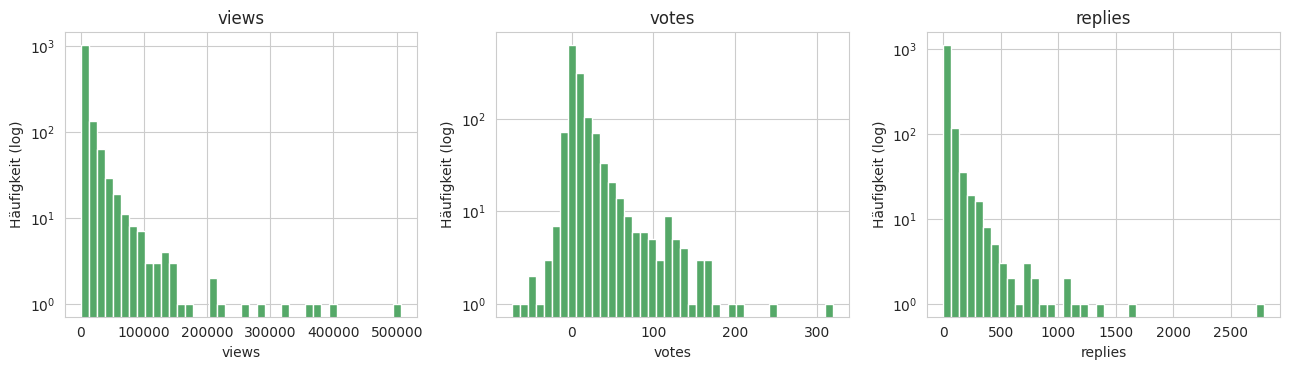

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col in zip(axes, numeric_cols):
    ax.hist(df[col].dropna(), bins=40, color="#55A868")
    ax.set_title(col)
    ax.set_yscale("log")
    ax.set_xlabel(col)
    ax.set_ylabel("Häufigkeit (log)")
plt.tight_layout()
plt.show()


### 5.3 Ausreißer via IQR-Regel

In [ ]:
outlier_summary = {}
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary[col] = {"Q1": q1, "Q3": q3, "IQR": iqr, "untere Grenze": lower, "obere Grenze": upper, "Ausreißer (n)": n_out}
pd.DataFrame(outlier_summary).T


,Q1,Q3,IQR,untere Grenze,obere Grenze,Ausreißer (n)
views,2191.75,11146.25,8954.5,-11240.0,24578.0,171.0
votes,1.00,14.00,13.0,-18.5,33.5,146.0
replies,5.00,45.00,40.0,-55.0,105.0,143.0


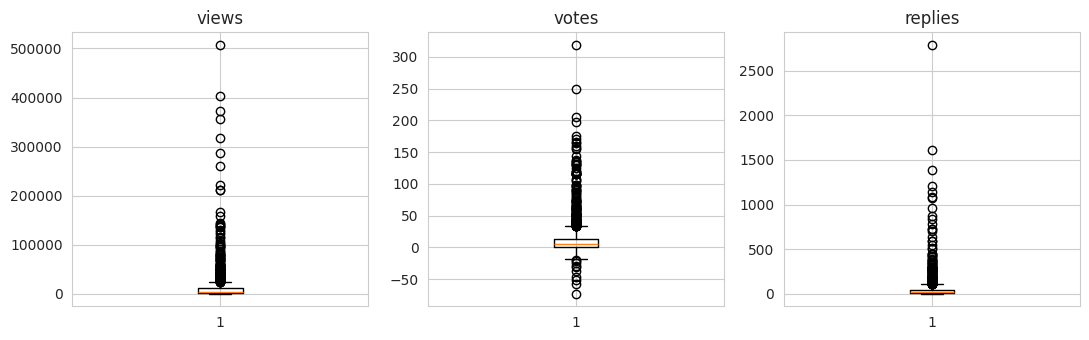

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, col in zip(axes, numeric_cols):
    ax.boxplot(df[col].dropna(), vert=True)
    ax.set_title(col)
plt.tight_layout()
plt.show()


## 6. Kategoriale Spalten

### 6.1 `parent_category` (grobe Kategorie)

In [ ]:
print(f"Eindeutige Werte: {df['parent_category'].nunique()}")
df["parent_category"].value_counts(dropna=False)


Eindeutige Werte: 12


parent_category
NaN                        501
Computers & Electronics    339
Home & Garden              207
Entertainment               43
Financial Services          35
Sports & Fitness            33
Beauty & Wellness           32
Automotive                  31
Restaurants                 29
Kids & Babies               26
Apparel                     25
Travel                      14
Small Business              11
Name: count, dtype: int64

### 6.2 `thread_category` (feingranulare Kategorie)

In [ ]:
print(f"Eindeutige Werte: {df['thread_category'].nunique()}")
df["thread_category"].value_counts(dropna=False).head(20)


Eindeutige Werte: 55


thread_category
Computers & Electronics            176
Other                               93
Home Improvement & Tools            89
Home & Garden                       84
Groceries                           77
Video Games                         77
Peripherals & Accessories           65
Appliances                          53
Computers & Tablets/eReaders        47
Apparel                             47
Home Theatre & Audio                40
Cell Phones                         35
Books, Music, Movies, Magazines     34
Sports & Fitness                    28
Beauty Supplies & Personal Care     26
Automotive                          23
Televisions                         21
Beauty & Wellness                   20
Auto Parts & Accessories            19
Outdoors & Patio                    19
Name: count, dtype: int64

### 6.3 `source` (Händler/Anbieter)

In [ ]:
print(f"Eindeutige Werte: {df['source'].nunique()}")
df["source"].value_counts(dropna=False).head(15)


Eindeutige Werte: 148


source
NaN                    339
Amazon.ca              213
Costco                 118
Home Depot              63
Walmart                 57
Canadian Tire           45
Best Buy                43
Princess Auto           27
Staples                 24
Dollarama               23
Visions Electronics     15
Microsoft Store         12
Dell                    11
The Source              11
Lenovo Canada           11
Name: count, dtype: int64

### 6.4 Visualisierung: Top-Kategorien

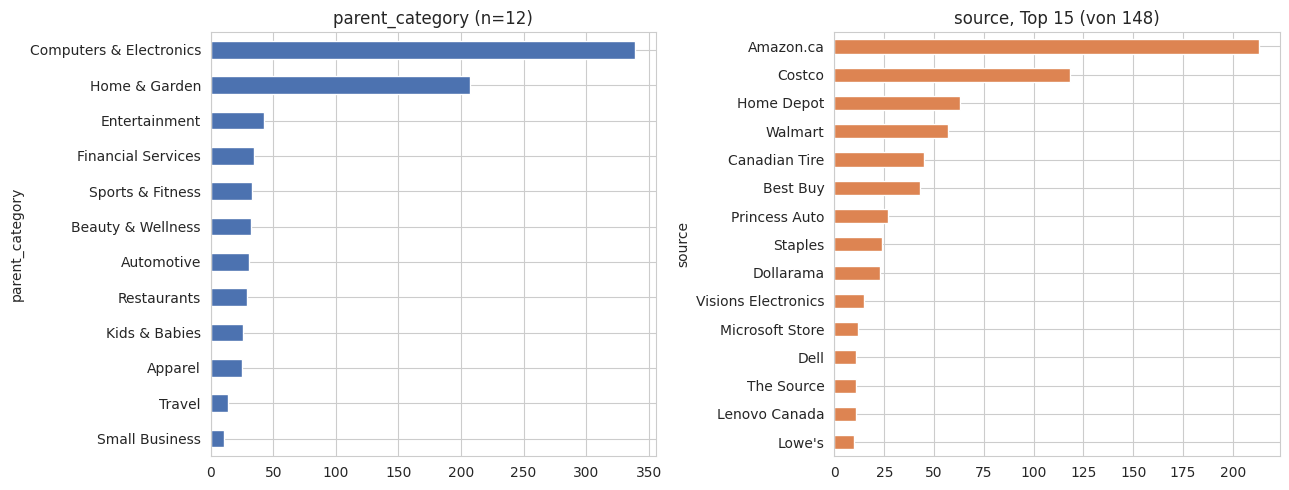

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
df["parent_category"].value_counts().plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("parent_category (n=" + str(df["parent_category"].nunique()) + ")")
axes[0].invert_yaxis()

top_source = df["source"].value_counts().head(15)
top_source.plot(kind="barh", ax=axes[1], color="#DD8452")
axes[1].set_title("source, Top 15 (von " + str(df["source"].nunique()) + ")")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()


## 7. Formatierungsfehler: `price` und `saving`

### 7.1 Rohwerte-Stichprobe

In [ ]:
df["price"].dropna().sample(15, random_state=42).tolist()

['39.88',
 '$179.99',
 '$19.97',
 '$5.99',
 '24.49',
 '$259.99',
 '47.97',
 '599.99',
 '399',
 '$174.99',
 '$789.99',
 '$140.00',
 '99.99',
 '449.00',
 '139.99']

### 7.2 Formatmuster-Klassifikation (price)

In [ ]:
def classify_price_format(s):
    s = str(s).strip()
    if re.fullmatch(r"\d+(\.\d+)?", s):
        return "rein numerisch (z.B. 39.99)"
    if re.fullmatch(r"\$\d+(\.\d+)?", s):
        return "Dollarzeichen + Zahl (z.B. $39.99)"
    if "%" in s:
        return "Prozentangabe"
    if "/" in s:
        return "Mengenangabe (z.B. $/lb)"
    if re.search(r"(USD|CAD)", s, re.IGNORECASE):
        return "Währungssuffix"
    if s.lower() in ("free", "varies"):
        return "Wortwert (free/varies)"
    if "-" in s:
        return "Preisspanne"
    return "sonstiges Format"

price_formats = df["price"].dropna().apply(classify_price_format).value_counts()
price_formats


price
rein numerisch (z.B. 39.99)           527
Dollarzeichen + Zahl (z.B. $39.99)    297
sonstiges Format                       36
Wortwert (free/varies)                 20
Währungssuffix                          7
Mengenangabe (z.B. $/lb)                4
Prozentangabe                           4
Preisspanne                             3
Name: count, dtype: int64

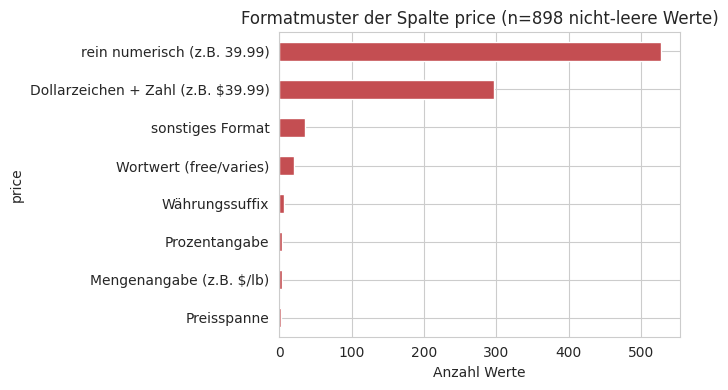

Anteil rein numerischer Werte: 58.7%


In [ ]:
fig, ax = plt.subplots(figsize=(7,4))
price_formats.sort_values().plot(kind="barh", ax=ax, color="#C44E52")
ax.set_xlabel("Anzahl Werte")
ax.set_title("Formatmuster der Spalte price (n=898 nicht-leere Werte)")
plt.tight_layout()
plt.show()
print(f"Anteil rein numerischer Werte: {price_formats.get('rein numerisch (z.B. 39.99)', 0) / df['price'].notna().sum() * 100:.1f}%")


### 7.3 Formatmuster-Klassifikation (saving)

In [ ]:
def classify_saving_format(s):
    s = str(s).strip()
    if "%" in s:
        return "Prozentangabe"
    if s.startswith("$"):
        return "Dollarbetrag"
    if "off" in s.lower():
        return "Wortkombination ('X off')"
    if re.fullmatch(r"\d+(\.\d+)?", s):
        return "reine Zahl (Einheit unklar)"
    return "sonstiges Format"

saving_formats = df["saving"].dropna().apply(classify_saving_format).value_counts()
saving_formats


saving
Prozentangabe                  335
Dollarbetrag                   131
reine Zahl (Einheit unklar)     26
sonstiges Format                22
Wortkombination ('X off')       10
Name: count, dtype: int64

### 7.4 Zeichenlängen-Verteilung als struktureller Indikator

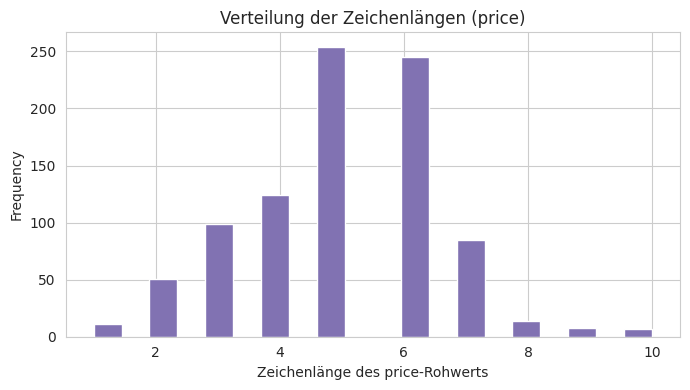

In [ ]:
fig, ax = plt.subplots(figsize=(7,4))
df["price"].dropna().astype(str).str.len().plot(kind="hist", bins=20, ax=ax, color="#8172B2")
ax.set_xlabel("Zeichenlänge des price-Rohwerts")
ax.set_title("Verteilung der Zeichenlängen (price)")
plt.tight_layout()
plt.show()


## 8. Semantische Heterogenität: `thread_category` vs. `parent_category`

### 8.1 Wie viele thread_category-Werte sind mehrdeutig?

In [ ]:
both = df[df["thread_category"].notna() & df["parent_category"].notna()]
mapping_counts = both.groupby("thread_category")["parent_category"].nunique().sort_values(ascending=False)
print(f"thread_category-Werte insgesamt (mit bekannter parent_category): {mapping_counts.shape[0]}")
print(f"davon mehrdeutig (>1 parent_category): {(mapping_counts > 1).sum()}")
mapping_counts[mapping_counts > 1]


thread_category-Werte insgesamt (mit bekannter parent_category): 42
davon mehrdeutig (>1 parent_category): 1


thread_category
Other    10
Name: parent_category, dtype: int64

### 8.2 Kreuztabelle (Ausschnitt)

In [ ]:
ct = pd.crosstab(both["thread_category"], both["parent_category"])
ct.loc[ct.sum(axis=1).sort_values(ascending=False).index].head(15)


parent_category,Apparel,Automotive,Beauty & Wellness,Computers & Electronics,Entertainment,Financial Services,Home & Garden,Kids & Babies,Restaurants,Small Business,Sports & Fitness,Travel
thread_category,,,,,,,,,,,,
Other,0,12,6,24,6,2,24,2,3,0,9,5
Home Improvement & Tools,0,0,0,0,0,0,89,0,0,0,0,0
Video Games,0,0,0,77,0,0,0,0,0,0,0,0
Peripherals & Accessories,0,0,0,65,0,0,0,0,0,0,0,0
Appliances,0,0,0,0,0,0,53,0,0,0,0,0
Computers & Tablets/eReaders,0,0,0,47,0,0,0,0,0,0,0,0
Home Theatre & Audio,0,0,0,40,0,0,0,0,0,0,0,0
Cell Phones,0,0,0,35,0,0,0,0,0,0,0,0
"Books, Music, Movies, Magazines",0,0,0,0,34,0,0,0,0,0,0,0


### 8.3 Zeilen ohne parent_category, aber mit thread_category (Imputationsbedarf)

In [ ]:
missing_parent = df[df["parent_category"].isna() & df["thread_category"].notna()]
print(f"Zeilen mit fehlender parent_category: {missing_parent.shape[0]}")
missing_parent["thread_category"].value_counts().head(10)


Zeilen mit fehlender parent_category: 500


thread_category
Computers & Electronics    176
Home & Garden               84
Groceries                   77
Apparel                     47
Sports & Fitness            28
Automotive                  23
Beauty & Wellness           20
Restaurants                 18
Financial Services           8
Kids & Babies                8
Name: count, dtype: int64

## 9. Zeitspalten

### 9.1 Parsing und Wertebereich

In [ ]:
for col in ["creation_date", "expiry", "last_reply"]:
    parsed = pd.to_datetime(df[col], errors="coerce")
    n_failed = df[col].notna().sum() - parsed.notna().sum()
    print(f"{col:15s}: {parsed.min()}  bis  {parsed.max()}   (nicht parsebar: {n_failed})")


creation_date  : 2018-07-14 12:00:00  bis  2020-07-17 08:06:00   (nicht parsebar: 890)
expiry         : 2020-03-01 00:00:00  bis  2021-01-01 00:00:00   (nicht parsebar: 0)
last_reply     : 2020-06-26 01:11:00  bis  2020-07-17 12:57:00   (nicht parsebar: 949)


### 9.2 Zeitliche Verteilung der Postings

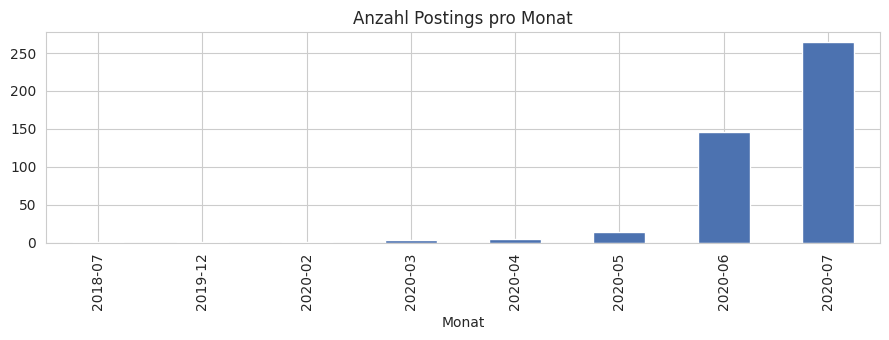

In [ ]:
creation = pd.to_datetime(df["creation_date"], errors="coerce")
fig, ax = plt.subplots(figsize=(9,3.5))
creation.dt.to_period("M").value_counts().sort_index().plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_title("Anzahl Postings pro Monat")
ax.set_xlabel("Monat")
plt.tight_layout()
plt.show()


## 10. Textspalte: `title`

### 10.1 Längenverteilung

count    1326.000000
mean       56.899698
std        22.259561
min         3.000000
25%        40.000000
50%        53.000000
75%        69.750000
max       120.000000
Name: title, dtype: float64


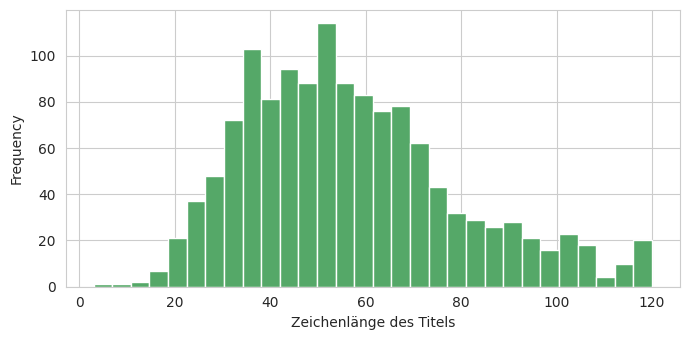

In [ ]:
title_len = df["title"].astype(str).str.len()
print(title_len.describe())
fig, ax = plt.subplots(figsize=(7,3.5))
title_len.plot(kind="hist", bins=30, ax=ax, color="#55A868")
ax.set_xlabel("Zeichenlänge des Titels")
plt.tight_layout()
plt.show()


### 10.2 Häufigste Wörter (nach einfacher Tokenisierung)

In [ ]:
from collections import Counter
stopwords = {"the","a","an","for","and","or","of","to","in","on","at","with","is","-","","$","%"}
tokens = []
for t in df["title"].dropna():
    tokens += [w.lower() for w in re.findall(r"[A-Za-zÀ-ÿ]+", str(t)) if w.lower() not in stopwords and len(w) > 2]
top_words = Counter(tokens).most_common(20)
pd.DataFrame(top_words, columns=["Wort", "Häufigkeit"])


,Wort,Häufigkeit
0,off,181
1,ymmv,112
2,free,108
3,pack,52
4,only,47
5,sale,44
6,july,43
7,set,38
8,pro,38
9,wireless,38


## 11. Zusammenfassung

In [ ]:
print("="*70)
print("ZUSAMMENFASSUNG DER EXPLORATIVEN ANALYSE")
print("="*70)
print(f"Datensatzgröße:              {df.shape[0]} Zeilen x {df.shape[1]} Spalten")
print()
print("Fehlende Werte (Top 3):")
for col, pct in missing['fehlend (%)'].head(3).items():
    print(f"  - {col:20s}: {pct:.1f}%")
print()
print(f"Exakte Duplikate (ganze Zeile): {n_exact_dupes}")
print(f"Duplikate nach identischer URL: {dup_checks['identische URL (url, ohne NaN)']}")
print()
print(f"parent_category: {df['parent_category'].nunique()} eindeutige Werte, {df['parent_category'].isna().sum()} fehlend")
print(f"thread_category: {df['thread_category'].nunique()} eindeutige Werte, {df['thread_category'].isna().sum()} fehlend")
print(f"source:          {df['source'].nunique()} eindeutige Werte, {df['source'].isna().sum()} fehlend")
print()
print(f"price:  {(price_formats.get('rein numerisch (z.B. 39.99)', 0) / df['price'].notna().sum() * 100):.0f}% der nicht-leeren Werte sind 'sauber' numerisch, Rest verteilt auf {len(price_formats)-1} weitere Formate")
print(f"Mehrdeutige thread_category-Werte (>1 parent_category): {(mapping_counts > 1).sum()} von {mapping_counts.shape[0]}")
print("="*70)


ZUSAMMENFASSUNG DER EXPLORATIVEN ANALYSE
Datensatzgröße:              1326 Zeilen x 15 Spalten

Fehlende Werte (Top 3):
  - expiry              : 72.1%
  - saving              : 60.5%
  - parent_category     : 37.8%

Exakte Duplikate (ganze Zeile): 0
Duplikate nach identischer URL: 50

parent_category: 12 eindeutige Werte, 501 fehlend
thread_category: 55 eindeutige Werte, 1 fehlend
source:          148 eindeutige Werte, 339 fehlend

price:  59% der nicht-leeren Werte sind 'sauber' numerisch, Rest verteilt auf 7 weitere Formate
Mehrdeutige thread_category-Werte (>1 parent_category): 1 von 42


**Fazit:** Der Datensatz zeigt in allen vier untersuchten Fehlerdimensionen
(Duplikate, fehlende Werte, Formatierungsfehler, semantische Heterogenität) reale,
nicht-triviale Ausprägungen und eignet sich damit als Datengrundlage für den
empirischen Vergleich klassischer ML-Verfahren und Claude in Kapitel 3 und 4 der
Masterarbeit.